# Is pooled AUROC measuring *who* or *when*?

Our models predict a participant's EMA suicide-risk label at time *t* from their
passive sensing in the preceding window. Evaluation is a per-participant cyclical
5-fold walk-forward: each person's ~28-day timeline is cut into 5 consecutive
chunks; in each round one chunk is tested and the model trains on that person's
other four chunks (minus a 120h purge buffer). Every survey is tested once, and all
out-of-fold predictions are pooled into one **pooled AUROC**.

This notebook checks what that pooled AUROC rewards. A score can be high because
the model separates **people** (high- vs low-base-rate participants), because it
tracks **change within a person** (risky vs calm surveys of the same person), or
both. Our stated goal is the second. The notebook:

1. shows on a toy example how pooled, person-centred and within-person AUROC behave;
2. runs XGBoost, a Transformer and a sensor-free baseline with the same
   `src/train.py` commands our sweeps use;
3. describes the label structure of our cohort;
4. decomposes each model's AUROC into between- and within-person parts;
5. looks at per-person predictions directly;
6. adds a control: shuffling labels within each person;
7. repeats the core check on a sample of the existing RQ1 sweep runs;
8. runs the same models under subject-wise CV, where identity cannot be memorised.

**Where to run it.** Section 2 submits SLURM jobs. Everything else reads files, but
run the kernel itself on a compute node (e.g. Jupyter started under `srun`), not on
the login node.

In [1]:
from __future__ import annotations

import os
import shlex
import subprocess
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from sklearn.metrics import roc_auc_score

# The repo root is wherever `.project-root` lives (the marker train.py also uses), so
# this works whether the kernel starts in notebooks/, the repo root, or elsewhere below.
_start = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd().resolve()
REPO = next(p for p in [_start, *_start.parents] if (p / ".project-root").exists())
os.chdir(REPO)
OUT = REPO / "logs" / "verify_between_person"
(OUT / "runs").mkdir(parents=True, exist_ok=True)

SEED = 7
N_BOOT = 1000
pd.set_option("display.width", 160)

## Metric helpers

All metrics take the pooled test predictions of one run: one row per survey with
`app_user_id`, `fold_index`, `record_timestamp`, `y_true` and the predicted
probability `p`.

* **Pooled AUROC** — what the pipeline reports.
* **Person-centred AUROC** — subtract each person's mean prediction first, so
  anything constant per person cancels and only "higher or lower than usual for
  this person" remains.
* **Within-person AUROC** — AUROC computed separately for each person with both
  outcomes, then averaged. Never compares two different people.
* **Between-person variance share** — fraction of the variance in predictions
  explained by which person a survey belongs to.

In [2]:
def load_preds(run_dir: str | Path) -> pd.DataFrame:
    df = pd.read_csv(Path(run_dir) / "pooled_predictions.csv")
    df = df[df.stage == "test"].copy()
    df["record_timestamp"] = pd.to_datetime(df["record_timestamp"])
    return df.rename(columns={"prob_class_1": "p"})[
        ["app_user_id", "fold_index", "record_timestamp", "y_true", "p"]
    ].reset_index(drop=True)


def pooled_auroc(df: pd.DataFrame, col: str = "p") -> float:
    return roc_auc_score(df.y_true, df[col])


def person_centred_auroc(df: pd.DataFrame, col: str = "p") -> float:
    centred = df[col] - df.groupby("app_user_id")[col].transform("mean")
    return roc_auc_score(df.y_true, centred)


def within_person_auroc(df: pd.DataFrame, col: str = "p") -> tuple[float, int]:
    """Mean of per-person AUROCs over people with both outcomes, and how many there are."""
    scores = [
        roc_auc_score(g.y_true, g[col]) for _, g in df.groupby("app_user_id") if g.y_true.nunique() == 2
    ]
    return (float(np.mean(scores)) if scores else np.nan), len(scores)


def between_person_share(df: pd.DataFrame, col: str = "p") -> float:
    user_mean = df.groupby("app_user_id")[col].transform("mean")
    total = ((df[col] - df[col].mean()) ** 2).sum()
    return float(((user_mean - df[col].mean()) ** 2).sum() / total) if total > 0 else np.nan


def summarize(df: pd.DataFrame, col: str = "p") -> dict:
    within, n_users = within_person_auroc(df, col)
    return dict(
        pooled=pooled_auroc(df, col),
        person_centred=person_centred_auroc(df, col),
        within_person=within,
        n_mixed_users=n_users,
        between_share=between_person_share(df, col),
        user_mean_vs_rate_r=df.groupby("app_user_id").agg(m=(col, "mean"), r=("y_true", "mean")).corr().iloc[0, 1],
    )


def cluster_bootstrap(df: pd.DataFrame, fn, n_boot: int = N_BOOT, seed: int = SEED) -> tuple[float, float]:
    """95% CI of fn(df) resampling whole participants with replacement."""
    rng = np.random.default_rng(seed)
    users = df.app_user_id.unique()
    groups = {u: g for u, g in df.groupby("app_user_id")}
    vals = []
    for _ in range(n_boot):
        pick = rng.choice(users, size=len(users), replace=True)
        sample = pd.concat(
            [groups[u].assign(app_user_id=f"{u}_{i}") for i, u in enumerate(pick)], ignore_index=True
        )
        try:
            v = fn(sample)
        except ValueError:  # a resample with a single class
            continue
        if np.isfinite(v):
            vals.append(v)
    return tuple(np.percentile(vals, [2.5, 97.5]))

## 1. The problem in miniature

Two people, four surveys each. The numbers are each model's predicted
probability that a survey is positive, the same `P(positive)` our models output.

| Survey | A's label | B's label |
|---|---|---|
| 1 | 0 | **1** (at risk) |
| 2 | 0 | 0 |
| 3 | 0 | **1** (at risk) |
| 4 | 0 | 0 |

A is never at risk. B is at risk on surveys 1 and 3.

**Model 1 knows only *who*.** It gives every survey from the same person the same
prediction: 0.10 for each of A's surveys, 0.80 for each of B's. It has learned
"A is low-risk, B is high-risk" and nothing else, so it cannot tell B's risky
surveys (1, 3) from B's calm ones (2, 4).

**Model 2 also knows *when*.** Same 0.10 for A, but its predictions for B move with
B's state: 0.90 on the risky surveys (1, 3), 0.30 on the calm ones (2, 4). That is
what our paper wants: detecting the moments a person is at risk.

| Survey | Model 1: A | Model 1: B | Model 2: A | Model 2: B |
|---|---|---|---|---|
| 1 | 0.10 | 0.80 | 0.10 | **0.90** |
| 2 | 0.10 | 0.80 | 0.10 | 0.30 |
| 3 | 0.10 | 0.80 | 0.10 | **0.90** |
| 4 | 0.10 | 0.80 | 0.10 | 0.30 |

### What person-centring does

Person-centring subtracts each person's **average prediction** from each of their
predictions, then computes AUROC on what is left. Anything constant for a person,
the "who", cancels out; only "higher or lower than usual for this person" remains.

* **Model 1:** A's average is 0.10, so each A prediction becomes 0.10 − 0.10 = 0.
  B's average is 0.80, so each B prediction becomes 0.80 − 0.80 = 0. Every survey
  now scores 0: the model has nothing left to rank with, and AUROC is 0.50 (chance).
* **Model 2:** A still becomes 0. B's average is (0.90 + 0.30 + 0.90 + 0.30) / 4 =
  0.60, so B's risky surveys become +0.30 and B's calm ones −0.30. The positive
  surveys (+0.30) still outrank every negative one (0 for A, −0.30 for B), so AUROC
  stays 1.00.

**Within-person AUROC** reaches the same verdict a different way: it never compares
A with B, only each person's surveys with that person's other surveys (here,
only B has both outcomes). Model 1's four identical B predictions give 0.50; Model
2's give 1.00.

**Pooled AUROC**, by contrast, gives Model 1 a good-looking 0.83: B's 0.80s outrank
all of A's 0.10s, even though it knows nothing about B's risky days. The cell below
computes all of this.

In [3]:
toy = pd.DataFrame(
    {
        "app_user_id": ["A"] * 4 + ["B"] * 4,
        "y_true": [0, 0, 0, 0, 1, 0, 1, 0],
        "model_1_who": [0.10] * 4 + [0.80] * 4,
        "model_2_when": [0.10] * 4 + [0.90, 0.30, 0.90, 0.30],
    }
)
for col in ["model_1_who", "model_2_when"]:
    person_mean = toy.groupby("app_user_id")[col].transform("mean")
    toy[f"{col}_centred"] = (toy[col] - person_mean).round(2)
print(toy.to_string(index=False))
print()
for col in ["model_1_who", "model_2_when"]:
    w, _ = within_person_auroc(toy, col)
    print(
        f"{col:13s} pooled {pooled_auroc(toy, col):.2f} | "
        f"person-centred {person_centred_auroc(toy, col):.2f} | within-person {w:.2f}"
    )

app_user_id  y_true  model_1_who  model_2_when  model_1_who_centred  model_2_when_centred
          A       0          0.1           0.1                  0.0                   0.0
          A       0          0.1           0.1                  0.0                   0.0
          A       0          0.1           0.1                  0.0                   0.0
          A       0          0.1           0.1                  0.0                   0.0
          B       1          0.8           0.9                  0.0                   0.3
          B       0          0.8           0.3                  0.0                  -0.3
          B       1          0.8           0.9                  0.0                   0.3
          B       0          0.8           0.3                  0.0                  -0.3

model_1_who   pooled 0.83 | person-centred 0.50 | within-person 0.50
model_2_when  pooled 1.00 | person-centred 1.00 | within-person 1.00


Model 1 scores 0.83 pooled with zero knowledge of *when* B is at risk; centring
removes its constant per-person offset and it drops to 0.50. Model 2 keeps its
score because its signal varies within B. Our real models (section 4) look like
Model 1.

## 2. Run the models with `src/train.py`

Every run is the same `uv run python src/train.py ...` command the RQ1 sweeps use:
the shared overrides in `BASE` (the sweeps' fixed settings, plus one sampler and
modality set) and a model-specific part in `RUNS`. To add a model, add a line to
`RUNS`.

`model=user_rate` is the **sensor-free baseline**: it predicts each participant's
positive rate in the training split of each fold and ignores the sensor data
entirely. It goes through the identical folds and 120h purge as the real models.

Each run writes to `logs/verify_between_person/runs/<name>`; runs whose
predictions already exist are not resubmitted.

In [4]:
BASE = [
    "eval_plan=cyclical",
    "task_name=verify_between_person",
    "logger=csv",
    "data/sampler=sweep_configs/rolling_72h_6h",
    "data/modalities=step_calorie_distance",
    "data/scaler=dual",
    "data.os_filter=both",
    "data.collapse_strategy=none",
    "data.use_demographics=false",
    "data.use_sleep=true",
    "data.sleep_feature_mode=hours_only",
    "data.use_survey_context=false",
    "data.require_sensor_data=true",
    "data.purge_hours=120.0",
    "trainer.max_epochs=75",
    "trainer.enable_checkpointing=false",
    "callbacks.model_checkpoint=null",
    "callbacks.early_stopping=null",
]

# name -> (model-specific overrides, SLURM resources)
CPU = ["--cpus-per-task=8", "--mem=48G", "--time=02:00:00"]
GPU = ["--gres=gpu:1", "--cpus-per-task=2", "--mem=16G", "--time=04:00:00"]  # training runs on the GPU
RUNS = {
    "baseline_user_rate": (["model=user_rate", "trainer=cpu"], CPU),
    "xgboost": (["model=flaml_xgboost", "model.automl_config.metric=roc_auc", "model.auto_class_weights=true", "trainer=cpu"], CPU),
    "transformer": (["model=transformer", "model.auto_class_weights=true", "trainer=gpu"], GPU),
    # "lstm": (["model=lstm", "model.auto_class_weights=true", "trainer=gpu"], GPU),
    # "chronos2": (["model=chronos2", "model.auto_class_weights=true", "trainer=gpu"], GPU),
}


def run_dir(name: str) -> Path:
    return OUT / "runs" / name


def train_command(name: str, runs: dict = RUNS, base: list = BASE) -> str:
    overrides, _ = runs[name]
    args = base + overrides + [f"hydra.run.dir={run_dir(name).relative_to(REPO)}"]
    return "uv run python src/train.py " + " ".join(shlex.quote(a) for a in args)


for name in RUNS:
    print(f"# {name}\n{train_command(name)}\n")

# baseline_user_rate
uv run python src/train.py eval_plan=cyclical task_name=verify_between_person logger=csv data/sampler=sweep_configs/rolling_72h_6h data/modalities=step_calorie_distance data/scaler=dual data.os_filter=both data.collapse_strategy=none data.use_demographics=false data.use_sleep=true data.sleep_feature_mode=hours_only data.use_survey_context=false data.require_sensor_data=true data.purge_hours=120.0 trainer.max_epochs=75 trainer.enable_checkpointing=false callbacks.model_checkpoint=null callbacks.early_stopping=null model=user_rate trainer=cpu hydra.run.dir=logs/verify_between_person/runs/baseline_user_rate

# xgboost
uv run python src/train.py eval_plan=cyclical task_name=verify_between_person logger=csv data/sampler=sweep_configs/rolling_72h_6h data/modalities=step_calorie_distance data/scaler=dual data.os_filter=both data.collapse_strategy=none data.use_demographics=false data.use_sleep=true data.sleep_feature_mode=hours_only data.use_survey_context=false data.requ

In [5]:
def submit(name: str, runs: dict = RUNS, base: list = BASE) -> str | None:
    if (run_dir(name) / "pooled_predictions.csv").exists():
        print(f"{name}: predictions already at {run_dir(name).relative_to(REPO)}")
        return None
    _, resources = runs[name]
    cmd = [
        "sbatch", "--parsable", "--partition=short", f"--job-name=vbp_{name}",
        f"--output={OUT.relative_to(REPO)}/{name}_%j.log", *resources, "--wrap", train_command(name, runs, base),
    ]
    job = subprocess.run(cmd, check=True, capture_output=True, text=True, cwd=REPO).stdout.strip()
    print(f"{name}: submitted job {job}")
    return job


def wait(jobs: list[str | None], poll_seconds: int = 30) -> None:
    pending = [j for j in jobs if j]
    while pending:
        out = subprocess.run(
            ["sacct", "-n", "-X", "-o", "JobID,State", "-j", ",".join(pending)], capture_output=True, text=True
        ).stdout
        states = dict(line.split()[:2] for line in out.strip().splitlines() if line.strip())
        done = {j: s for j, s in states.items() if s not in ("PENDING", "RUNNING", "REQUEUED")}
        for j, s in done.items():
            print(f"job {j}: {s}")
        pending = [j for j in pending if j not in done]
        if pending:
            time.sleep(poll_seconds)

Set `SUBMIT = True` to (re)create any run without saved predictions. With the
runs already on disk, leave it off and go straight to loading them.

In [6]:
SUBMIT = False
if SUBMIT:
    wait([submit(name) for name in RUNS])

In [7]:
missing = [name for name in RUNS if not (run_dir(name) / "pooled_predictions.csv").exists()]
if missing:
    raise FileNotFoundError(f"no saved predictions for {missing}; set SUBMIT = True above to run them")
preds = {name: load_preds(run_dir(name)) for name in RUNS}
print({name: f"{len(df)} surveys from {run_dir(name).relative_to(REPO)}" for name, df in preds.items()})

{'baseline_user_rate': '1258 surveys from logs/verify_between_person/runs/baseline_user_rate', 'xgboost': '1258 surveys from logs/verify_between_person/runs/xgboost', 'transformer': '1258 surveys from logs/verify_between_person/runs/transformer'}


## 3. Label structure of our cohort

Pooled AUROC can only be dominated by between-person differences if people differ
a lot in base rate. The evaluated surveys are the rows of any run's predictions.

group
always negative    18
mixed              12
always positive     1

1258 surveys, 31 participants, prevalence 0.185
                 surveys  positives
group                              
always negative      737          0
always positive       23         23
mixed                498        210

surveys evaluated per run: {'baseline_user_rate': 1258, 'xgboost': 1258, 'transformer': 1258}


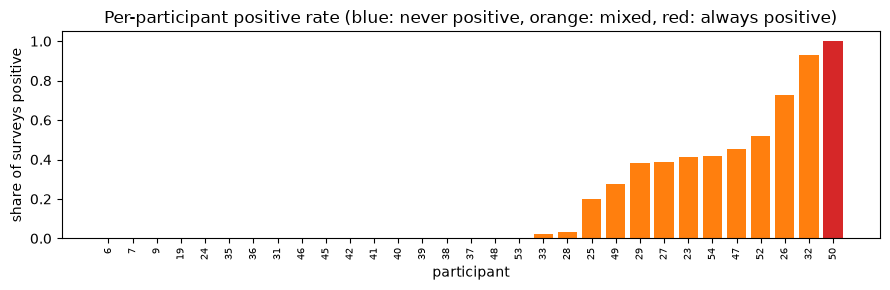

In [8]:
def label_structure(df: pd.DataFrame) -> pd.DataFrame:
    per_user = df.groupby("app_user_id").y_true.agg(n="size", positives="sum", rate="mean")
    per_user["group"] = np.select(
        [per_user.rate == 0, per_user.rate == 1], ["always negative", "always positive"], "mixed"
    )
    return per_user.sort_values("rate")


cohort = label_structure(preds["transformer"])
print(cohort.group.value_counts().to_string())
print(f"\n{int(cohort.n.sum())} surveys, {len(cohort)} participants, prevalence {cohort.positives.sum() / cohort.n.sum():.3f}")
print(cohort.groupby("group").agg(surveys=("n", "sum"), positives=("positives", "sum")).to_string())
print("\nsurveys evaluated per run:", {name: len(df) for name, df in preds.items()})

fig, ax = plt.subplots(figsize=(9, 3))
colors = cohort.group.map({"always negative": "tab:blue", "mixed": "tab:orange", "always positive": "tab:red"})
ax.bar(range(len(cohort)), cohort.rate, color=colors)
ax.set_xticks(range(len(cohort)), cohort.index, rotation=90, fontsize=7)
ax.set_ylabel("share of surveys positive")
ax.set_xlabel("participant")
ax.set_title("Per-participant positive rate (blue: never positive, orange: mixed, red: always positive)")
fig.tight_layout()
plt.show()

Only the *mixed* participants can show within-person signal at all. Every survey
from an always-negative or always-positive person can only help pooled AUROC by
being ranked relative to *other people's* surveys.

## 4. Between- vs within-person decomposition

CIs resample whole participants (1,000 bootstrap draws).

In [9]:
rows = []
for name, df in preds.items():
    row = dict(model=name, **summarize(df))
    row["pooled_ci"] = "[{:.2f}, {:.2f}]".format(*cluster_bootstrap(df, pooled_auroc))
    row["within_ci"] = "[{:.2f}, {:.2f}]".format(*cluster_bootstrap(df, lambda d: within_person_auroc(d)[0]))
    rows.append(row)
core = pd.DataFrame(rows).set_index("model")
print(core.round(3).to_string())

                    pooled  person_centred  within_person  n_mixed_users  between_share  user_mean_vs_rate_r     pooled_ci     within_ci
model                                                                                                                                   
baseline_user_rate   0.913           0.357          0.351             12          0.924                0.995  [0.82, 0.97]  [0.26, 0.45]
xgboost              0.783           0.448          0.372             12          0.535                0.926  [0.65, 0.89]  [0.31, 0.44]
transformer          0.778           0.548          0.518             12          0.399                0.785  [0.65, 0.86]  [0.43, 0.61]


Read across a row: a model whose pooled AUROC is far above its person-centred and
within-person AUROC gets its score from separating people.

**`baseline_user_rate`** (`model=user_rate`) uses no sensor data at all. In each
fold it looks up each participant's share of positive surveys in that fold's
training data and predicts that same number for every one of their test surveys;
a participant with no training surveys gets the overall training rate. It is the
"who only" strategy of Model 1 in section 1, applied to real labels. A sensor model
that does not beat it has not shown any use of the sensor data beyond identifying
the person.

**Why within-person AUROC can fall *below* 0.5.** The baseline scores far below
chance within-person, and XGBoost is also below 0.5. This is a property of
leave-one-chunk-out learning, not a model failure: a person's positive rate in
their *other* four chunks is lowest exactly when the held-out chunk holds more of
their positives. So a model that learns "this person's usual rate" from training
is pushed *down* in the chunk where the person was most at risk. Below-chance
within-person scores are a further sign of person-level rather than survey-level
prediction.

## 5. Looking inside the predictions

One panel per model for one fold: each column is a participant (sorted by their
positive rate), each dot a survey, coloured by its label. Flat columns mean the
model gives that person roughly the same score every time.

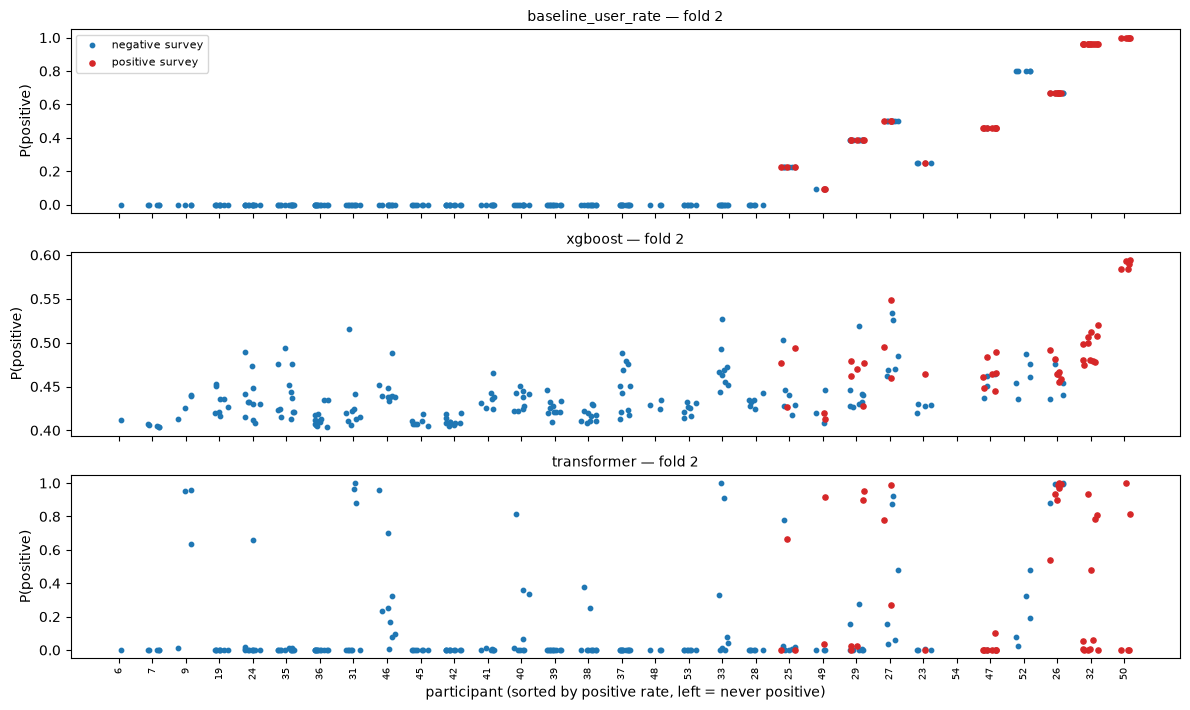

In [10]:
FOLD = 2
users_sorted = cohort.index.tolist()
xpos = {u: i for i, u in enumerate(users_sorted)}
fig, axes = plt.subplots(len(preds), 1, figsize=(12, 2.4 * len(preds)), sharex=True)
axes = np.atleast_1d(axes)
for ax, (name, df) in zip(axes, preds.items()):
    d = df[(df.fold_index == FOLD) & df.app_user_id.isin(xpos)]
    x = d.app_user_id.map(xpos).values + np.random.default_rng(SEED).uniform(-0.25, 0.25, len(d))
    neg, pos = (d.y_true == 0).values, (d.y_true == 1).values
    ax.scatter(x[neg], d.p.values[neg], s=10, c="tab:blue", label="negative survey")
    ax.scatter(x[pos], d.p.values[pos], s=14, c="tab:red", label="positive survey")
    ax.set_ylabel("P(positive)")
    ax.set_title(f"{name} — fold {FOLD}", fontsize=10)
axes[0].legend(loc="upper left", fontsize=8)
axes[-1].set_xticks(range(len(users_sorted)), users_sorted, rotation=90, fontsize=7)
axes[-1].set_xlabel("participant (sorted by positive rate, left = never positive)")
fig.tight_layout()
plt.show()

In [11]:
for name, df in preds.items():
    per_user = (
        df[df.fold_index == FOLD]
        .groupby("app_user_id")
        .agg(n=("y_true", "size"), pos_rate=("y_true", "mean"), pred_mean=("p", "mean"), pred_sd=("p", "std"))
        .sort_values("pos_rate")
    )
    r = per_user.pos_rate.corr(per_user.pred_mean)
    print(f"\n{name}: corr(participant positive rate, mean prediction) in fold {FOLD} = {r:.2f}")
    print(per_user.round(2).to_string())


baseline_user_rate: corr(participant positive rate, mean prediction) in fold 2 = 0.85
              n  pos_rate  pred_mean  pred_sd
app_user_id                                  
6             1      0.00       0.00      NaN
7             5      0.00       0.00      0.0
9             4      0.00       0.00      0.0
19            8      0.00       0.00      0.0
24           11      0.00       0.00      0.0
35           12      0.00       0.00      0.0
31            9      0.00       0.00      0.0
28            6      0.00       0.00      0.0
36           12      0.00       0.00      0.0
33            9      0.00       0.00      0.0
42           10      0.00       0.00      0.0
41            7      0.00       0.00      0.0
40            9      0.00       0.00      0.0
39           10      0.00       0.00      0.0
38           10      0.00       0.00      0.0
37           11      0.00       0.00      0.0
48            3      0.00       0.00      0.0
52            5      0.00       0.80   

## 6. Control: shuffle labels within each person

Keep every model's predictions fixed, but shuffle each participant's labels among
their own surveys. This keeps every person's positive rate (the "who") and destroys
which surveys were positive (the "when"). A model that tracks within-person change
should lose pooled AUROC under shuffling; a model that only separates people should
barely notice. We repeat the shuffle 200 times.

In [12]:
N_SHUFFLE = 200
rng = np.random.default_rng(SEED)
shuffle_rows = []
for name, df in preds.items():
    observed = pooled_auroc(df)
    shuffled = np.array([
        roc_auc_score(df.groupby("app_user_id").y_true.transform(lambda s: rng.permutation(s.values)), df.p)
        for _ in range(N_SHUFFLE)
    ])
    shuffle_rows.append(
        dict(
            model=name,
            pooled_observed=observed,
            pooled_shuffled_mean=shuffled.mean(),
            shuffled_95=f"[{np.percentile(shuffled, 2.5):.2f}, {np.percentile(shuffled, 97.5):.2f}]",
            lift_kept_after_shuffle=(shuffled.mean() - 0.5) / (observed - 0.5),
        )
    )
print(pd.DataFrame(shuffle_rows).set_index("model").round(3).to_string())

                    pooled_observed  pooled_shuffled_mean   shuffled_95  lift_kept_after_shuffle
model                                                                                           
baseline_user_rate            0.913                 0.938  [0.93, 0.95]                    1.061
xgboost                       0.783                 0.818  [0.80, 0.84]                    1.125
transformer                   0.778                 0.773  [0.75, 0.79]                    0.981


`lift_kept_after_shuffle` is the share of the model's lift above chance (0.5) that
survives when only each person's label rate is kept. Values near 1 mean the pooled
score is almost entirely between-person.

## 7. Does it hold across the sweep? (sample of existing runs)

The saved RQ1 sweep runs share the same data settings as above. We take a small
sample of raw-window (no featurizer) runs — 4 models × 3 lookback/bin settings ×
2 modality sets, latest run of each — and compute the same decomposition. No
retraining. These runs have no `user_rate` counterpart, so the baseline here is
computed from each run's predictions: each person's positive rate in their other
folds (this ignores the purge, so it runs slightly higher than `user_rate`).

In [13]:
SWEEP_ROOT = REPO / "logs" / "cyclical_sweep" / "runs"
SAMPLE_MODELS = ["SimpleLSTM", "SimpleTransformer", "xgboost", "lrl1"]
SAMPLE_SAMPLERS = [(24.0, "4h"), (72.0, "6h"), (120.0, "12h")]
SAMPLE_MODALITIES = ["step", "step+calorie+distance"]


def run_meta(d: Path) -> dict | None:
    try:
        c = yaml.safe_load(open(d / ".hydra" / "config.yaml"))
    except (OSError, yaml.YAMLError):
        return None
    data, model = c.get("data", {}), c.get("model", {})
    net = model.get("net") if isinstance(model.get("net"), dict) else {}
    estimators = (model.get("automl_config") or {}).get("estimator_list")
    featurizer = model.get("featurizer") if isinstance(model.get("featurizer"), dict) else {}
    return dict(
        run=d,
        model=estimators[0] if estimators else net.get("_target_", "").rsplit(".", 1)[-1],
        lookback=data.get("sampler", {}).get("lookback_hours"),
        freq=data.get("sampler", {}).get("resample_freq"),
        modalities="+".join(data.get("modalities", [])),
        # RQ2's feature sweep reuses the same output root with a catch22/summary-stats
        # featurizer; RQ1 feeds the raw flattened window.
        featurizer=featurizer.get("_target_", "none").rsplit(".", 1)[-1],
    )


def other_fold_rate_auroc(df: pd.DataFrame) -> float:
    """Pooled AUROC of predicting each survey with its person's positive rate in their other folds."""
    stats = df.groupby(["app_user_id", "fold_index"]).y_true.agg(["sum", "count"])
    tot = stats.groupby("app_user_id").sum().reindex(df.app_user_id)
    own = stats.reindex(pd.MultiIndex.from_arrays([df.app_user_id, df.fold_index]))
    other_n = tot["count"].values - own["count"].values
    other_pos = tot["sum"].values - own["sum"].values
    rate = np.where(other_n > 0, other_pos / np.maximum(other_n, 1), df.y_true.mean())
    return roc_auc_score(df.y_true, rate)


inventory = pd.DataFrame(
    [m for d in sorted(SWEEP_ROOT.glob("*/")) if (d / "pooled_predictions.csv").exists() and (m := run_meta(d))]
)
sample = inventory[
    (inventory.featurizer == "none")
    & inventory.model.isin(SAMPLE_MODELS)
    & inventory.apply(lambda r: (r.lookback, r.freq) in SAMPLE_SAMPLERS, axis=1)
    & inventory.modalities.isin(SAMPLE_MODALITIES)
].sort_values("run").groupby(["model", "lookback", "freq", "modalities"]).tail(1)
print(f"{len(inventory)} sweep runs with predictions; {len(sample)} in the sample")

sweep_rows = []
for _, r in sample.iterrows():
    df = load_preds(r.run)
    s = summarize(df)
    sweep_rows.append(
        dict(
            model=r.model, lookback=int(r.lookback), freq=r.freq, modalities=r.modalities,
            pooled=s["pooled"], baseline_pooled=other_fold_rate_auroc(df),
            person_centred=s["person_centred"], within_person=s["within_person"],
            n_mixed=s["n_mixed_users"], between_share=s["between_share"],
        )
    )
sweep = pd.DataFrame(sweep_rows).sort_values(["modalities", "lookback", "model"])
print(sweep.round(3).to_string(index=False))

979 sweep runs with predictions; 20 in the sample


            model  lookback freq            modalities  pooled  baseline_pooled  person_centred  within_person  n_mixed  between_share
SimpleTransformer        24   4h                  step   0.821            0.924           0.539          0.479       11          0.574
             lrl1        24   4h                  step   0.683            0.930           0.520          0.539       12          0.385
          xgboost        24   4h                  step   0.742            0.924           0.456          0.414       11          0.388
SimpleTransformer        72   6h                  step   0.818            0.931           0.556          0.521       11          0.489
       SimpleLSTM       120  12h                  step   0.659            0.930           0.474          0.363       12          0.270
SimpleTransformer       120  12h                  step   0.727            0.930           0.522          0.544       12          0.375
             lrl1       120  12h                  step 

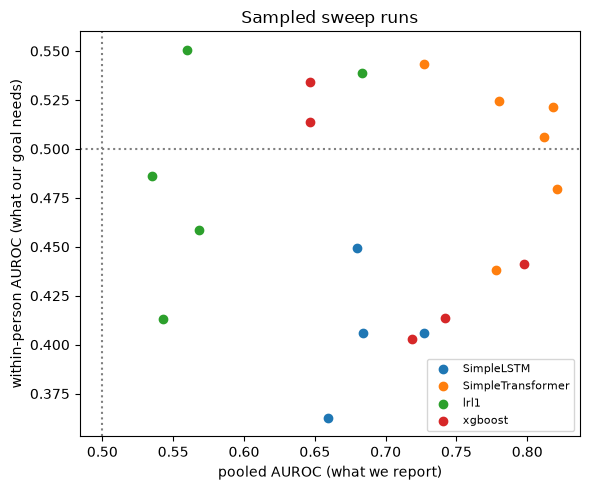

Spearman correlation across sampled runs, pooled vs between-person share: 0.83
Spearman correlation across sampled runs, pooled vs within-person: -0.01


In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
for model, g in sweep.groupby("model"):
    ax.scatter(g.pooled, g.within_person, label=model)
ax.axhline(0.5, color="grey", ls=":")
ax.axvline(0.5, color="grey", ls=":")
ax.set_xlabel("pooled AUROC (what we report)")
ax.set_ylabel("within-person AUROC (what our goal needs)")
ax.set_title("Sampled sweep runs")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print("Spearman correlation across sampled runs, pooled vs between-person share:",
      round(sweep[["pooled", "between_share"]].corr(method="spearman").iloc[0, 1], 2))
print("Spearman correlation across sampled runs, pooled vs within-person:",
      round(sweep[["pooled", "within_person"]].corr(method="spearman").iloc[0, 1], 2))

If runs spread along the pooled axis while staying near 0.5 within-person, the
differences we report between models and temporal settings are differences in how
well they separate people, not in how well they detect momentary risk.

## 8. Subject-wise cross-validation: does anything generalize to new people?

Sections 4–7 show the cyclical scheme rewards recognising people the model has
already seen. Subject-wise CV (`eval_plan=user_cv`) removes that shortcut: each
fold trains on some participants and tests on participants the model has **never
seen**, so identity cannot be memorised. It answers a different question: *given a
new person's passive sensing, can we tell whether their surveys are likely to be
positive, using only patterns learned from other people?*

Setup: one round of 5 folds, grouped by participant and stratified by whether they
were ever positive; a validation set of unseen training users is carved out of
each training pool. Same data settings as section 2. `test=true` is required:
`configs/train.yaml` defaults it to false, and without it `user_cv` only reports
validation metrics.

Expectations:
* The `user_rate` baseline can only predict the overall training rate for an
  unseen person, so it must score exactly 0.5. Anything else would mean identity
  leaks.
* A sensor model above 0.5 is using sensor patterns that generalise across people.

Caveat: for a held-out person, the dual scaler's per-subject part is fit on that
person's own windows over the whole study (no labels involved). That assumes a
deployed system already knows a new user's baseline activity.

In [15]:
UCV_BASE = [o for o in BASE if not o.startswith(("eval_plan=", "data.purge_hours="))] + [
    "eval_plan=user_cv",
    "test=true",
    "data.num_repeats=1",
]
UCV_RUNS = {f"user_cv_{name}": spec for name, spec in RUNS.items()}

for name in UCV_RUNS:
    print(f"# {name}\n{train_command(name, UCV_RUNS, UCV_BASE)}\n")

SUBMIT_UCV = False
if SUBMIT_UCV:
    wait([submit(name, UCV_RUNS, UCV_BASE) for name in UCV_RUNS])

missing = [name for name in UCV_RUNS if not (run_dir(name) / "pooled_predictions.csv").exists()]
if missing:
    raise FileNotFoundError(f"no saved predictions for {missing}; set SUBMIT_UCV = True above to run them")
ucv_preds = {name: load_preds(run_dir(name)) for name in UCV_RUNS}
print({name: f"{len(df)} surveys, {df.app_user_id.nunique()} participants" for name, df in ucv_preds.items()})

# user_cv_baseline_user_rate
uv run python src/train.py task_name=verify_between_person logger=csv data/sampler=sweep_configs/rolling_72h_6h data/modalities=step_calorie_distance data/scaler=dual data.os_filter=both data.collapse_strategy=none data.use_demographics=false data.use_sleep=true data.sleep_feature_mode=hours_only data.use_survey_context=false data.require_sensor_data=true trainer.max_epochs=75 trainer.enable_checkpointing=false callbacks.model_checkpoint=null callbacks.early_stopping=null eval_plan=user_cv test=true data.num_repeats=1 model=user_rate trainer=cpu hydra.run.dir=logs/verify_between_person/runs/user_cv_baseline_user_rate

# user_cv_xgboost
uv run python src/train.py task_name=verify_between_person logger=csv data/sampler=sweep_configs/rolling_72h_6h data/modalities=step_calorie_distance data/scaler=dual data.os_filter=both data.collapse_strategy=none data.use_demographics=false data.use_sleep=true data.sleep_feature_mode=hours_only data.use_survey_context=false

Per-fold test AUROC is the scheme's native summary (mean ± SD over the 5 folds;
each fold's test users are an independent draw). With one round, every survey is
tested exactly once, so a pooled AUROC over all folds is also available, but read
it with care: each fold's model is trained on different people, so pooling mixes
scores from five different models. The baseline shows the problem: it predicts one
constant per fold (that fold's training rate) and scores 0.5 in every fold, yet its
pooled AUROC is not 0.5, because pooling just compares the folds' training rates
with their test users' outcomes. Use the per-fold mean as the headline here.
Within-person AUROC is computed on held-out participants with both outcomes.

In [16]:
ucv_rows = []
for name, df in ucv_preds.items():
    per_fold = [pooled_auroc(g) for _, g in df.groupby("fold_index") if g.y_true.nunique() == 2]
    s = summarize(df)
    ucv_rows.append(
        dict(
            model=name.removeprefix("user_cv_"),
            fold_auroc_mean=np.mean(per_fold),
            fold_auroc_sd=np.std(per_fold, ddof=1),
            folds=len(per_fold),
            pooled=s["pooled"],
            pooled_ci="[{:.2f}, {:.2f}]".format(*cluster_bootstrap(df, pooled_auroc)),
            within_person=s["within_person"],
            n_mixed_users=s["n_mixed_users"],
            person_centred=s["person_centred"],
        )
    )
ucv = pd.DataFrame(ucv_rows).set_index("model")
print("Subject-wise CV (unseen participants):")
print(ucv.round(3).to_string())

comparison = pd.DataFrame(
    {
        "cyclical_pooled": core["pooled"],
        "subject_wise_pooled": ucv["pooled"],
        "subject_wise_fold_mean": ucv["fold_auroc_mean"],
    }
)
print("\nSame models, both schemes:")
print(comparison.round(3).to_string())

Subject-wise CV (unseen participants):
                    fold_auroc_mean  fold_auroc_sd  folds  pooled     pooled_ci  within_person  n_mixed_users  person_centred
model                                                                                                                        
baseline_user_rate            0.500          0.000      5   0.382  [0.20, 0.63]          0.500             12           0.509
xgboost                       0.453          0.103      5   0.443  [0.27, 0.59]          0.601             12           0.509
transformer                   0.343          0.149      5   0.390  [0.26, 0.52]          0.479             12           0.593

Same models, both schemes:
                    cyclical_pooled  subject_wise_pooled  subject_wise_fold_mean
model                                                                           
baseline_user_rate            0.913                0.382                   0.500
xgboost                       0.783                0.443    

Read the comparison row by row: the drop from cyclical to subject-wise pooled AUROC
is roughly how much of the cyclical score came from recognising people the model
had seen. What remains above 0.5 under subject-wise CV is signal that transfers to
new people.

## 9. What this tells us

Numbers are from the runs of 2026-10-02 (72h lookback, 6h bins, all three
modalities, 1,258 surveys from 31 participants). Re-check them against the
outputs above if runs are regenerated. FLAML's time-budgeted search is not
deterministic, so XGBoost's numbers move by a few points between runs.

1. **No sensor model beats the sensor-free baseline.** Predicting each
   participant's training-split positive rate reaches pooled AUROC 0.91; XGBoost
   and the Transformer reach about 0.78.
2. **No model shows clear within-person signal.** Within-person AUROC is 0.37 for
   XGBoost and 0.52 for the Transformer, whose CI (0.43–0.61) includes 0.5.
   Person-centred AUROC is 0.45 and 0.55. Our stated goal — detecting a person's
   own risky moments — is not supported on this configuration.
3. **Shuffling labels within each person changes nothing.** Every model keeps all
   of its pooled AUROC lift when we scramble *which* of a person's surveys were
   positive. The pooled scores are between-person.
4. **The pattern holds across the sampled sweep runs.** Across 20 RQ1 runs
   (4 models × 3 lookback/bin settings × 2 modality sets), pooled AUROC rises with
   the between-person share of the predictions (Spearman ≈ 0.8) and is unrelated to
   within-person AUROC (≈ 0). Differences in pooled AUROC between models and
   temporal settings track how well each separates people.
5. **Nothing generalises to new people.** Under subject-wise CV (one round of 5
   folds, 35 participants, models never see the test participants), the baseline
   is exactly 0.5 as it must be, and the sensor models are at or below chance:
   mean per-fold AUROC 0.45 ± 0.10 for XGBoost and 0.34 ± 0.15 for the
   Transformer. Their cyclical scores of about 0.78 do not survive removing the
   chance to recognise people. Within-person AUROC on held-out participants is
   0.60 (XGBoost) and 0.48 (Transformer), on 12 people.

**Overall:** in this configuration the sensor models' apparent performance comes
from recognising participants they were trained on. We find no evidence that the
passive sensing predicts survey risk either for new people (subject-wise) or
within a known person over time (within-person metrics). Below-chance subject-wise
scores with 5 folds of ~7 participants are most likely noise plus person-specific
patterns that do not transfer, not a meaningful inverse signal.

**Why:** 18 of 31 participants are never positive and one is always positive, so
most surveys can only contribute to pooled AUROC through comparisons with other
people. The cyclical design trains on each person's other chunks, so any model can
learn who is high-risk, and that alone is enough to score well.

**Limits.** Within-person metrics rest on the 12 participants with both outcomes,
so they are noisy: a small within-person effect (the Transformer's 0.52) cannot be
ruled out or confirmed. The sensor-free baseline and the shuffle control do not
depend on those 12 people.